In [1]:
import seaborn as sns               # matplotlib 을 더 쉽고 예쁘게 쓰게 해 주는 그래프 라이브러리 (별명 sns)
import pandas as pd                 # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt     # seaborn 이 내부에서 쓰는 그래프 라이브러리 (plt.show() 에 필요)

## Capital Bike Share

- 공유 자전거 회사의 데이터
- 미국 수도인워싱턴DC에서 2012년 1년 동안 일별로 공유자전거 대여 건수를 모아 놓은 데이터이다.





In [2]:
# 하루 = 한 행. 2012년 366일(윤년)치 데이터라서 366행
# 주요 열
#   month, day     : 월, 일
#   workingday     : 근무일 여부 (y = 평일 근무일, n = 주말·공휴일)
#   holiday        : 공휴일 여부 (y = 공휴일, n = 공휴일 아님)
#   registered     : 회원(정기 이용자)의 대여 건수
#   casual         : 비회원(일회성 이용자)의 대여 건수
#   total          : 전체 대여 건수 (registered + casual)
df = pd.read_csv('data/bike.csv')
df

,month,day,quarter,day_of_week,workingday,holiday,temperature,humidity,windspeed,registered,casual,total
0,1,1,1Q,SUN,n,n,21.4,72,12,1608,686,2294
1,1,2,1Q,MON,n,y,15.0,44,19,1707,244,1951
2,1,3,1Q,TUE,y,n,7.6,39,23,2147,89,2236
3,1,4,1Q,WED,y,n,0.4,35,11,2273,95,2368
4,1,5,1Q,THU,y,n,14.2,49,6,3132,140,3272
...,...,...,...,...,...,...,...,...,...,...,...,...
361,12,27,4Q,THU,y,n,10.0,83,24,1867,247,2114
362,12,28,4Q,FRI,y,n,14.0,45,10,2451,644,3095
363,12,29,4Q,SAT,n,n,14.9,72,9,1182,159,1341
364,12,30,4Q,SUN,n,n,16.5,54,26,1432,364,1796


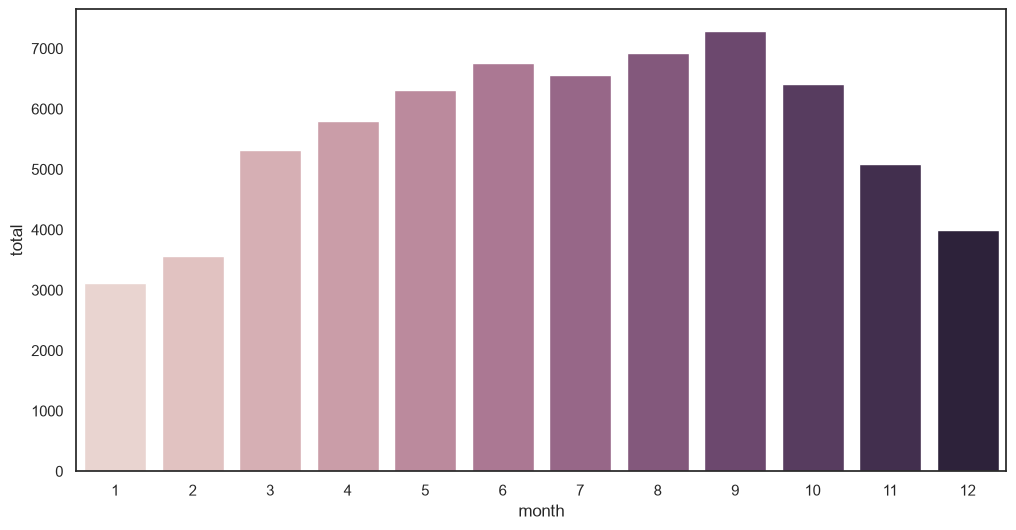

In [3]:
# [월별 하루 평균 대여 건수]
# sns.barplot 은 값을 그대로 그리지 않고, x 값이 같은 행끼리 모아서 '평균'을 막대로 그림
#   예) month 가 1인 행이 31개(1월 1일~31일) → 그 31개의 total 평균이 1월 막대의 높이
# data : 사용할 데이터프레임 / x : x축 열 / y : 평균을 낼 열
# errorbar=None : 막대 위에 생기는 검은 세로선(평균이 얼마나 믿을 만한지 나타내는 오차 막대)을 숨김
# hue='month', legend=False : 막대마다 색을 다르게 칠하기 위한 것 (분석 의미는 없음, 범례는 숨김)
# 결과 : 겨울(1월 약 3,100건)에 가장 적고 9월(약 7,300건)에 가장 많음 → 따뜻할수록 많이 탐
# 언제 쓰면 효과적인가? 그룹(월, 요일, 분기 등)별 평균을 비교할 때. 그룹 수가 적을수록 읽기 쉬움
#   단, 평균 하나만 보여 주므로 값이 얼마나 퍼져 있는지는 알 수 없음 → 그건 아래 stripplot / boxplot 으로
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.barplot(data=df, x= 'month', y='total',errorbar=None, hue='month',legend=False)
plt.show()

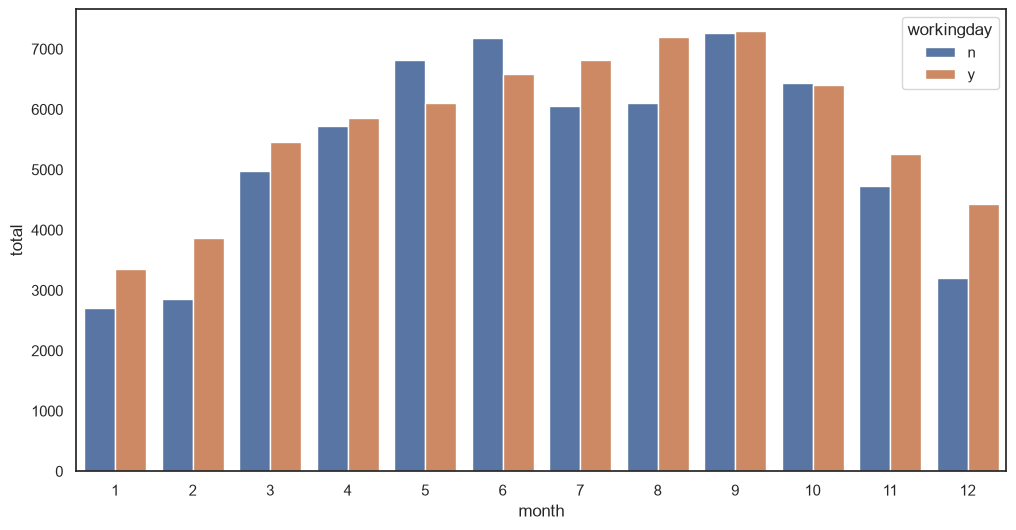

In [4]:
# [hue 로 그룹 나누기 : 월별 평균을 근무일 / 쉬는 날로 쪼개서 비교]
# hue='workingday' : 각 월의 데이터를 workingday 값(y, n)에 따라 두 그룹으로 나눈 뒤
#                    그룹마다 따로 평균을 내서, 색이 다른 막대 2개로 나란히 그림
#   예) 1월 31일 중 근무일(y)인 날들의 total 평균 → 막대 1개
#                   쉬는 날(n)인 날들의 total 평균 → 막대 1개
#   그래서 월마다 막대가 2개씩 생기고, 오른쪽 범례가 어느 색이 y / n 인지 알려 줌
# 읽는 법 : 같은 월 안에서 두 막대의 높이를 비교 → "근무일과 쉬는 날 중 언제 더 많이 빌리나?"
# 결과 : 12달 중 9달은 근무일(y)이 조금 더 높고 5·6·10월은 쉬는 날(n)이 더 높음. 어느 쪽이든 차이가 크지 않음
#        (연평균 근무일 약 5,700건 vs 쉬는 날 약 5,300건)
#        → 전체 합계만 봐서는 뚜렷한 차이가 안 보임. 그래서 아래에서 회원 / 비회원으로 나눠서 다시 봄
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.barplot(data=df, x= 'month', y='total',errorbar=None, hue='workingday')
plt.show()

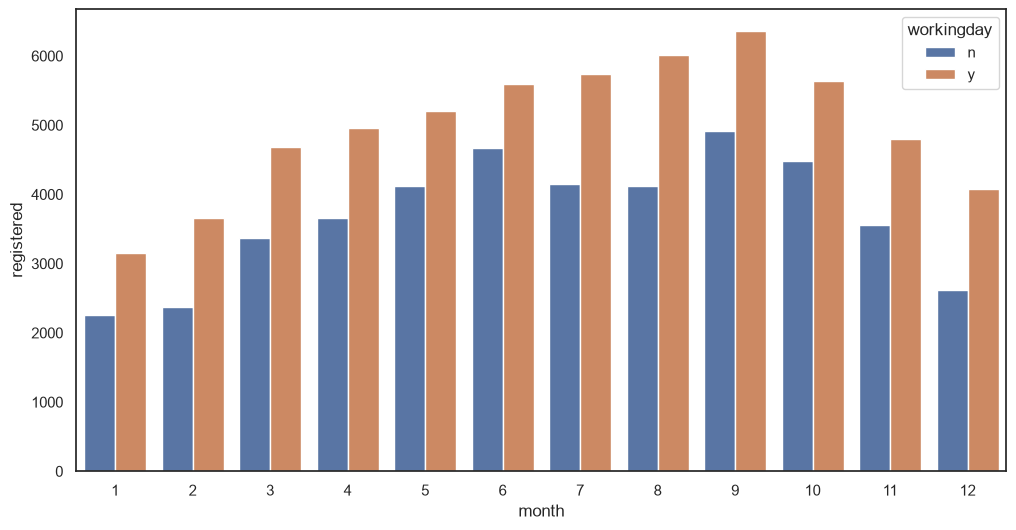

In [5]:
# [회원(registered)만 보기] y 를 total → registered 로 바꿈
# 결과 : 모든 달에서 근무일(y) 막대가 쉬는 날(n) 막대보다 확실히 높음
#        (연평균 근무일 약 5,000건 vs 쉬는 날 약 3,700건)
# 해석 : 회원은 근무일에 더 많이 탄다 → 출퇴근용으로 자전거를 쓰는 사람들이라고 볼 수 있음
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.barplot(data=df, x= 'month', y='registered',errorbar=None, hue='workingday')
plt.show()

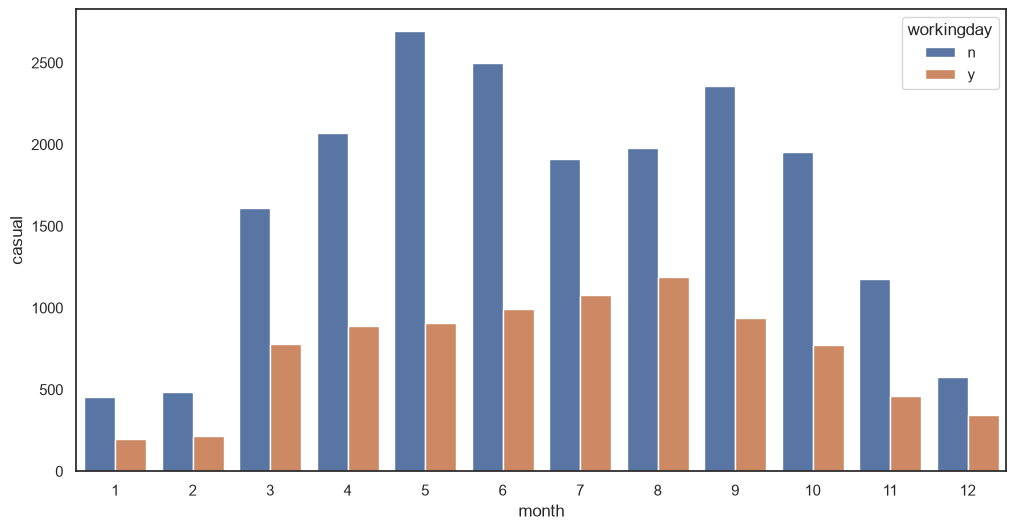

In [6]:
# [비회원(casual)만 보기] y 를 casual 로 바꿈
# 결과 : 회원과 정반대. 모든 달에서 쉬는 날(n) 막대가 근무일(y) 막대보다 훨씬 높음 (달에 따라 약 1.7~3배)
#        (연평균 쉬는 날 약 1,600건 vs 근무일 약 740건)
# 해석 : 비회원은 쉬는 날에 많이 탄다 → 나들이·관광용으로 가끔 빌리는 사람들이라고 볼 수 있음
# 정리 : total 에서 차이가 안 보였던 이유
#        = 회원(근무일에 많음)과 비회원(쉬는 날에 많음)이 서로 반대라서 합치면 차이가 상쇄됐기 때문
#        → hue 와 y 를 바꿔 가며 쪼개 보면, 합계에 숨어 있던 패턴을 찾을 수 있음
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.barplot(data=df, x= 'month', y='casual',errorbar=None, hue='workingday') 
plt.show()

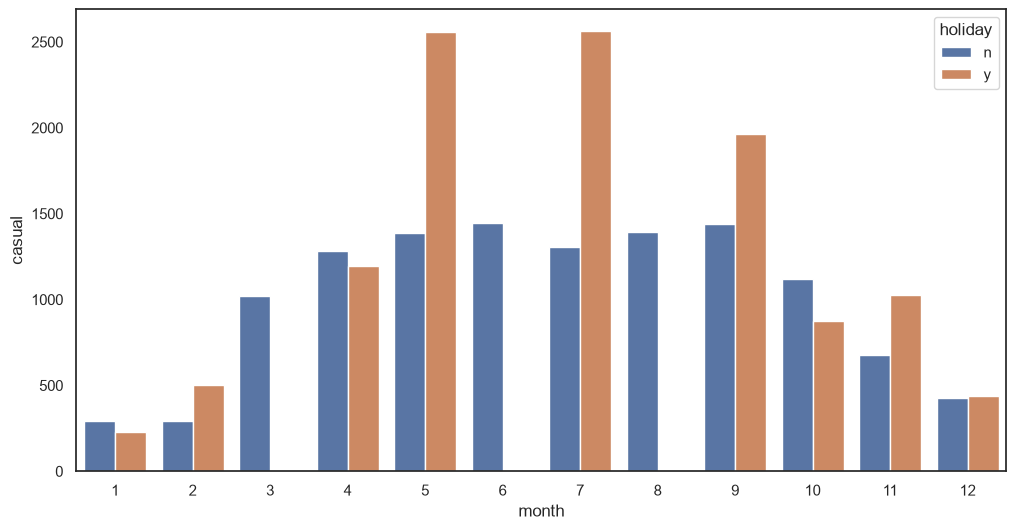

In [7]:
# [hue 를 holiday 로 바꾸기 : 공휴일(y) / 공휴일 아닌 날(n) 로 나눠서 비교]
# workingday 와의 차이 : workingday 의 n 은 주말 + 공휴일, holiday 의 y 는 공휴일만 (주말은 n 에 포함)
# 주의 1 : 3월, 6월, 8월에는 y 막대가 없음 → 그 달에 공휴일이 하루도 없어서 평균을 낼 데이터가 없기 때문
# 주의 2 : 공휴일은 1년에 11일뿐이라, y 막대는 그 달의 공휴일 1~2일만으로 낸 평균임
#          → 그날 날씨 같은 우연에 크게 흔들리므로 월마다 들쭉날쭉함 (5월·7월은 y 가 n 의 약 2배인데, 1월·4월·10월은 오히려 n 이 더 높음)
# 해석 : 이 그래프만으로 "공휴일에 비회원이 더 많이 탄다"고 결론 내리기는 어려움
#        그룹에 속한 데이터 개수가 너무 적으면 평균을 믿기 어렵다는 것을 보여 주는 예
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.barplot(data=df, x= 'month', y='casual',errorbar=None, hue='holiday') 
plt.show()

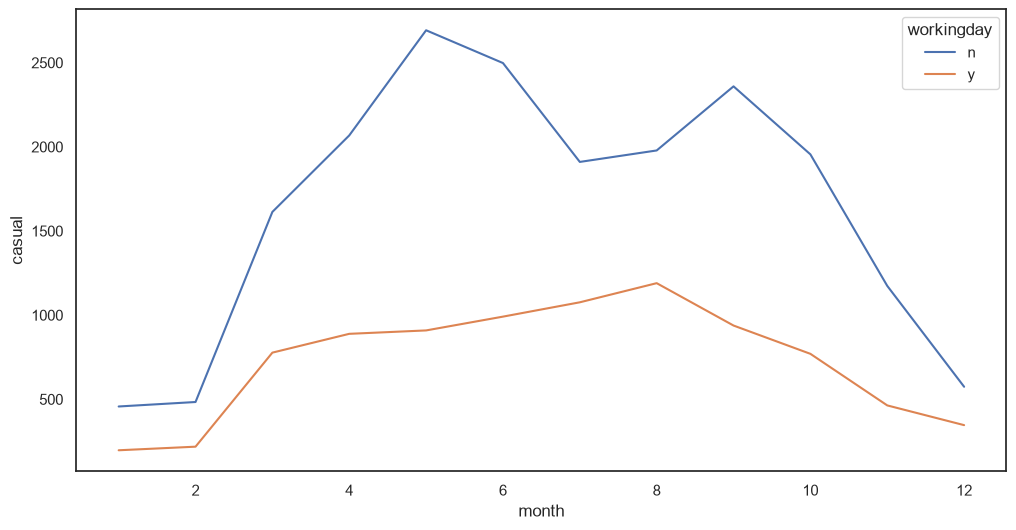

In [8]:
# [같은 내용을 선 그래프로] barplot → lineplot
# lineplot 도 barplot 처럼 x 값이 같은 행끼리 평균을 낸 뒤, 그 평균들을 선으로 이음
# hue='workingday' : 그룹마다 선을 따로 그림 → 근무일(y) 선 1개, 쉬는 날(n) 선 1개
# 막대 그래프보다 좋은 점 : 월이 지나면서 값이 어떻게 변하는지(추세)와 두 그룹의 간격이 한눈에 보임
# 언제 쓰면 효과적인가? x 가 시간처럼 순서가 있는 값(월, 연도)이고, 변화의 흐름을 보고 싶을 때
#   x 가 순서 없는 그룹(요일 이름, 지역 등)이면 선으로 잇는 게 의미가 없으니 barplot 이 맞음
# 결과 : 쉬는 날(n) 선이 1년 내내 근무일(y) 선보다 위에 있고, 4~6월과 9~10월에 간격이 가장 크게 벌어짐 (한여름 7~8월엔 조금 좁아짐)
#        → 비회원은 날씨 좋은 계절의 쉬는 날에 특히 많이 탄다
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.lineplot(data=df, x= 'month', y='casual',errorbar=None, hue='workingday') 
plt.show()

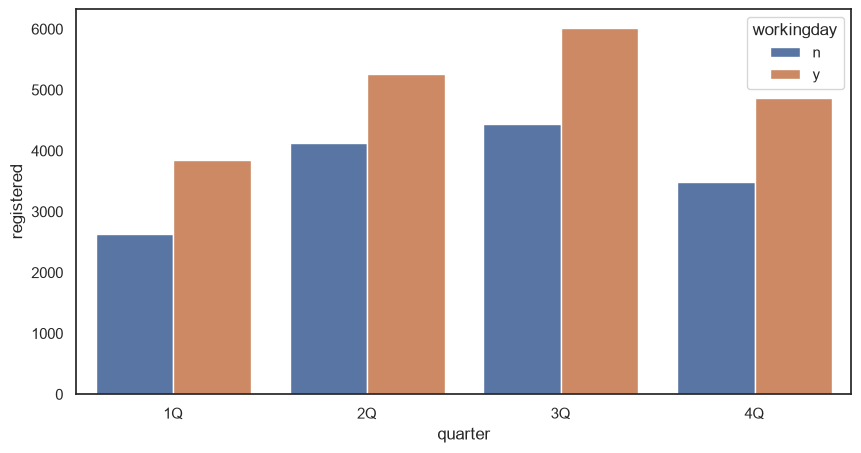

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

bike_df = pd.read_csv('data/bike.csv')
sns.set_theme(rc={'figure.figsize': (10, 5)}, style='white')

# 여기에 코드를 작성하세요.
# [실습] 분기별 회원(registered) 하루 평균 대여 건수를 근무일 / 쉬는 날로 나눠서 비교
# x='quarter' : 월(12칸) 대신 분기(1Q~4Q, 4칸)로 묶어서 봄 → 칸이 적어서 큰 흐름이 더 잘 보임
#               (1Q = 1~3월, 2Q = 4~6월, 3Q = 7~9월, 4Q = 10~12월)
# 결과 : 모든 분기에서 근무일(y)이 쉬는 날(n)보다 약 1,100~1,600건 많음
#        3Q(여름~초가을)가 가장 많고 (근무일 약 6,000건), 1Q(겨울)가 가장 적음 (쉬는 날 약 2,600건)
# 해석 : 월별로 봤던 "회원은 근무일에 더 많이 탄다"는 결론이 분기로 묶어도 똑같이 나옴
sns.barplot(data=bike_df, x= 'quarter', y='registered',errorbar=None, hue='workingday')
plt.show()


## Stripplot & Swarmplot

stripplot와 swarmplot 이 두가지 그래프는
로우가 수십 개에서 수백 개 정도 되는
비교적 작은 데이터셋을 분석 할 때 사용하는 것을 추천한다. 

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 같은 자전거 데이터를 다시 읽기 (366행 = 2012년 하루하루)
df = pd.read_csv('data/bike.csv')
df

,month,day,quarter,day_of_week,workingday,holiday,temperature,humidity,windspeed,registered,casual,total
0,1,1,1Q,SUN,n,n,21.4,72,12,1608,686,2294
1,1,2,1Q,MON,n,y,15.0,44,19,1707,244,1951
2,1,3,1Q,TUE,y,n,7.6,39,23,2147,89,2236
3,1,4,1Q,WED,y,n,0.4,35,11,2273,95,2368
4,1,5,1Q,THU,y,n,14.2,49,6,3132,140,3272
...,...,...,...,...,...,...,...,...,...,...,...,...
361,12,27,4Q,THU,y,n,10.0,83,24,1867,247,2114
362,12,28,4Q,FRI,y,n,14.0,45,10,2451,644,3095
363,12,29,4Q,SAT,n,n,14.9,72,9,1182,159,1341
364,12,30,4Q,SUN,n,n,16.5,54,26,1432,364,1796


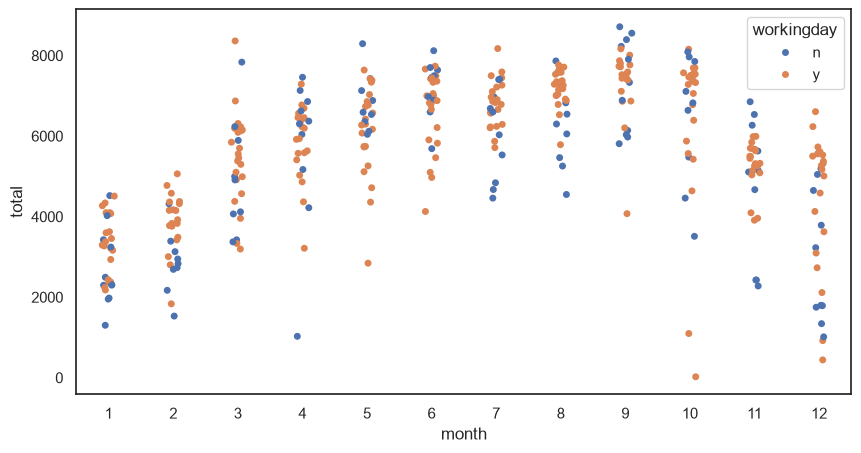

In [11]:
# [stripplot : 데이터 하나하나를 점으로 전부 찍는 그래프]
# barplot 은 평균 하나만 막대로 보여 주지만, stripplot 은 하루 = 점 1개로 모든 날을 다 보여 줌
#   → 각 월 칸에 점이 약 30개(그 달의 날 수)씩 세로로 찍힘. 점의 높이 = 그날의 대여 건수
# 점이 한 줄로 겹치지 않도록 좌우로 살짝 흩뿌려서(jitter) 찍음. 좌우 위치에는 의미가 없음
# hue='workingday' : 근무일(y) / 쉬는 날(n) 을 점 색으로 구분
#
# 언제 쓰면 효과적인가?
#   - 데이터가 수십~수백 개 정도로 적을 때 (수천 개가 넘으면 점이 뭉개져서 안 보임)
#   - 평균만으로는 안 보이는 것 : 값이 얼마나 퍼져 있는지, 유난히 튀는 날(이상치)이 있는지 볼 때
#
# 이 그래프의 내용
#   - 5~10월은 점들이 대부분 6,000~7,500 근처에 몰려 있고, 1~2월은 2,000~4,000 근처
#   - 12월은 점이 위아래로 넓게 퍼져 있음 → 연말·크리스마스(12/24~26)에 대여가 확 줄었기 때문
#   - 같은 달 안에서도 아래로 뚝 떨어진 점들이 있음 → 날씨가 나빴거나 특별한 날
#     예) 10월 맨 아래 점(22건) = 2012년 10월 29일, 허리케인 샌디가 워싱턴DC 를 덮친 날
#     (막대 그래프의 평균만 봤으면 몰랐을 정보)
#   - 근무일(y) 점이 훨씬 많음 → 1년 중 근무일이 250일, 쉬는 날이 116일이기 때문
sns.stripplot(data=df, x='month', y='total',hue='workingday')
plt.show()

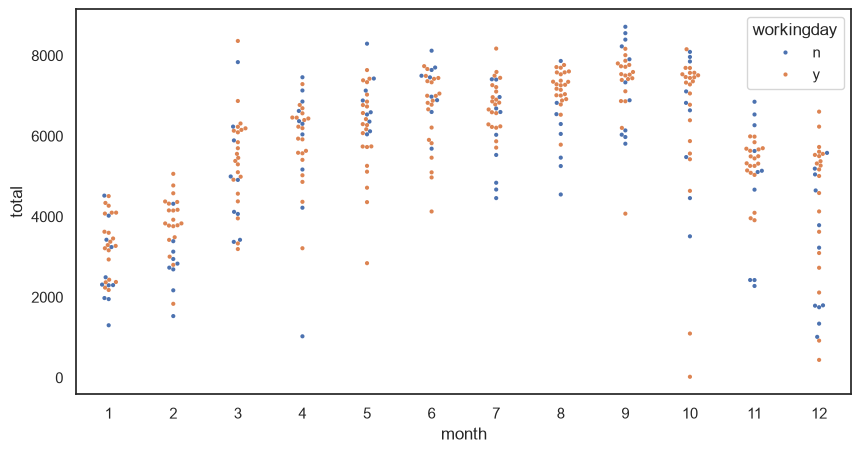

In [12]:
# [swarmplot : stripplot 과 같지만, 점끼리 겹치지 않게 옆으로 펼쳐서 찍는 그래프]
# stripplot 은 무작위로 흩뿌려서 점이 겹칠 수 있음 → 몇 개인지 세기 어려움
# swarmplot 은 같은 높이의 점들을 좌우로 차곡차곡 늘어놓음 → 벌집(swarm)처럼 퍼진 모양
#   → 옆으로 넓게 퍼진 곳 = 그 값 근처에 날이 많이 몰려 있다는 뜻 (분포의 모양이 보임)
# size=3 : 점 크기 (기본 5). 점이 많아서 칸 안에 다 안 들어가면 UserWarning 이 떠서 크기를 줄임
#
# 언제 쓰면 효과적인가?
#   - stripplot 처럼 데이터가 적을 때. 점이 많으면 칸을 넘쳐서 오히려 stripplot 보다 못함
#   - 값이 어디에 많이 몰려 있는지(분포 모양)까지 보고 싶을 때
#
# 이 그래프의 내용 : stripplot 과 같은 데이터라 결론도 같음
#   - 각 월에서 옆으로 가장 넓게 퍼진 높이가 그 달에 가장 흔한 대여 건수
#   - 겨울엔 아래쪽, 여름~가을엔 위쪽이 넓게 퍼져 있음
sns.swarmplot(data=df, x='month', y='total',hue='workingday',size=3)
plt.show()

## 실습

- 월별 기온 정보를 한눈에 볼 수 있는 stripplot을 그려보자.

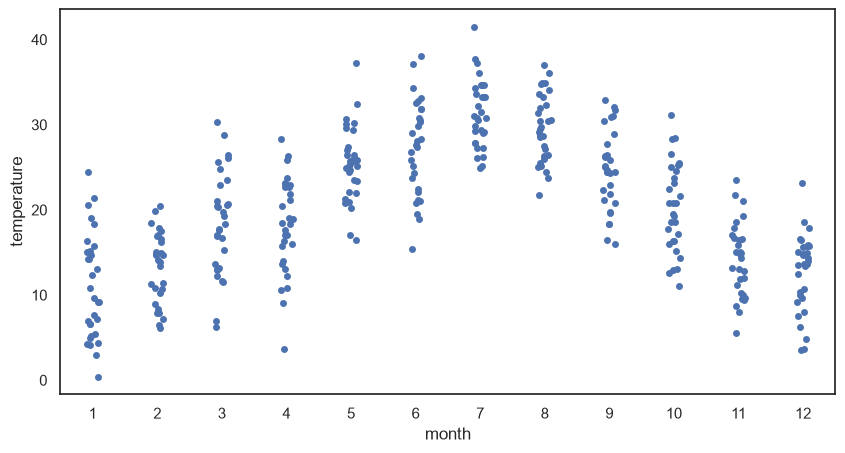

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

bike_df = pd.read_csv('data/bike.csv')
sns.set_theme(rc={'figure.figsize': (10, 5)}, style='white')

# [실습] 월별 기온을 stripplot 으로 (점 1개 = 하루의 기온)
# hue 를 안 쓰면 그룹을 나누지 않고, 월마다 색만 다르게 칠해짐
# 결과 : 1월 중간값 약 9.6도 → 7월 약 30.8도로 가장 더움 → 12월 약 13.7도로 다시 내려감
#        같은 달 안에서도 점이 위아래로 길게 퍼져 있음 (1월은 0.4도 ~ 24.4도)
#        → 평균 기온 하나보다, 그 달에 얼마나 춥고 더운 날이 섞여 있었는지가 한눈에 보임
# 참고 : 맨 위 대여 건수 막대 그래프와 모양이 비슷함 → 기온이 높을수록 자전거를 많이 탄다는 근거
sns.stripplot(data=bike_df, x='month',y='temperature')
plt.show()

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('data/bike.csv')
df

,month,day,quarter,day_of_week,workingday,holiday,temperature,humidity,windspeed,registered,casual,total
0,1,1,1Q,SUN,n,n,21.4,72,12,1608,686,2294
1,1,2,1Q,MON,n,y,15.0,44,19,1707,244,1951
2,1,3,1Q,TUE,y,n,7.6,39,23,2147,89,2236
3,1,4,1Q,WED,y,n,0.4,35,11,2273,95,2368
4,1,5,1Q,THU,y,n,14.2,49,6,3132,140,3272
...,...,...,...,...,...,...,...,...,...,...,...,...
361,12,27,4Q,THU,y,n,10.0,83,24,1867,247,2114
362,12,28,4Q,FRI,y,n,14.0,45,10,2451,644,3095
363,12,29,4Q,SAT,n,n,14.9,72,9,1182,159,1341
364,12,30,4Q,SUN,n,n,16.5,54,26,1432,364,1796


<Axes: xlabel='day_of_week', ylabel='registered'>

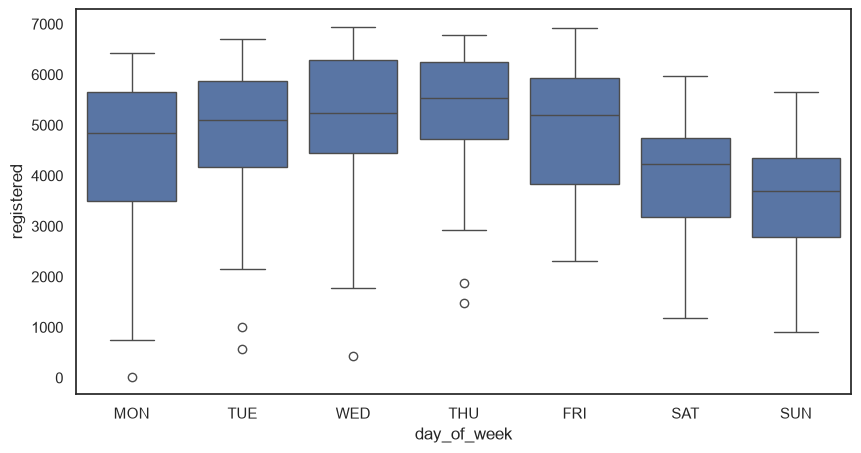

In [15]:
# [boxplot : 데이터가 퍼진 범위를 상자 하나로 요약하는 그래프]
# 상자 읽는 법 (아래에서 위로)
#   - 상자 아래 끝 : 1사분위수(25%) → 작은 값부터 줄 세웠을 때 1/4 지점
#   - 상자 가운데 선 : 중앙값(50%) → 딱 가운데 값
#   - 상자 위 끝 : 3사분위수(75%)
#   - 상자 높이 = IQR (가운데 50% 데이터가 들어 있는 범위)
#   - 위아래로 뻗은 선(whisker) : 이상치가 아닌 값 중 가장 작은 / 큰 값까지
#   - 선 밖의 동그라미 : 이상치 (상자에서 IQR 의 1.5배보다 더 멀리 떨어진 값)
# order=[...] : x축 순서를 직접 정함. 안 쓰면 데이터에 나온 순서대로 그려져서 요일이 뒤죽박죽 됨
#
# 언제 쓰면 효과적인가?
#   - 여러 그룹(여기선 요일 7개)의 분포를 나란히 비교할 때
#   - 데이터가 많아서 stripplot / swarmplot 으로는 점이 뭉개질 때 (몇 개든 상자 하나로 요약됨)
#   - 이상치를 찾을 때
#
# 이 그래프의 내용 : 요일별 회원(registered) 대여 건수
#   - 평일(월~금)의 중앙값이 약 4,800~5,500건으로, 주말(토 약 4,200 / 일 약 3,700)보다 높음
#     → 회원은 출퇴근용으로 쓴다는 앞의 결론과 같음
#   - 월~목에는 아래쪽에 이상치(동그라미)가 있음 → 평일인데 유난히 적게 빌린 날
#     월요일 20건 = 10월 29일 허리케인 샌디가 온 날 / 화요일 573건 = 크리스마스(12/25) / 수요일 432건 = 12/26
#     → 이상치를 발견하면 "그날 무슨 일이 있었나?"를 찾아보는 게 분석의 시작
sns.boxplot(data=df, x='day_of_week', y='registered',order=['MON','TUE','WED','THU','FRI','SAT','SUN'])

### 바이올린 플롯
 - 흰 점은 중간값에 해당하는 지점
 - 굵은 선 : IQR
 - 얇은 선 : 박스 플롯에서 Whisker의 위치랑 같음

<Axes: xlabel='day_of_week', ylabel='registered'>

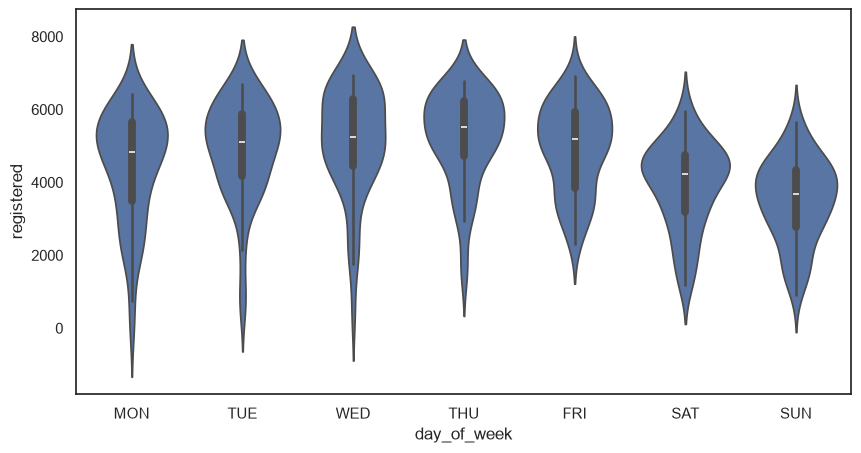

In [16]:
# [violinplot : boxplot 에 '데이터가 어디에 몰려 있는지'를 더한 그래프]
# 바이올린의 폭 = 그 높이에 데이터가 얼마나 많은지 (폭이 넓을수록 그 값 근처에 날이 많음)
# 안쪽의 흰 점 = 중앙값, 굵은 선 = IQR(상자), 얇은 선 = whisker → 안에 작은 boxplot 이 들어 있는 셈
#
# boxplot 과의 차이
#   boxplot 은 25%, 50%, 75% 위치만 알려 줘서, 데이터가 한 곳에 몰렸는지 두 곳으로 나뉘었는지는 모름
#   violinplot 은 모양 자체를 보여 줘서 그런 차이까지 보임
#
# 언제 쓰면 효과적인가?
#   - 그룹별 분포의 '모양'까지 비교하고 싶을 때
#   - 데이터가 많아서 점을 다 찍기 어려울 때
#
# 이 그래프의 내용
#   - 평일(특히 화~목) 바이올린은 위쪽(5,000~6,000 근처)이 볼록 → 대부분의 평일에 많이 빌림
#     아래로 길게 늘어진 꼬리 = 가끔 있는 적게 빌린 날 (boxplot 의 이상치들)
#   - 주말 바이올린은 볼록한 부분이 더 아래(3,000~4,500 근처)에 있음
#   - 바이올린이 실제 최솟값 / 최댓값보다 조금 삐져나오는 건, 모양을 부드럽게 그리느라 생긴 것 (실제 데이터는 없음)
sns.violinplot(data=df, x='day_of_week', y='registered',order=['MON','TUE','WED','THU','FRI','SAT','SUN'])

#### Histogram

<Axes: xlabel='registered', ylabel='Count'>

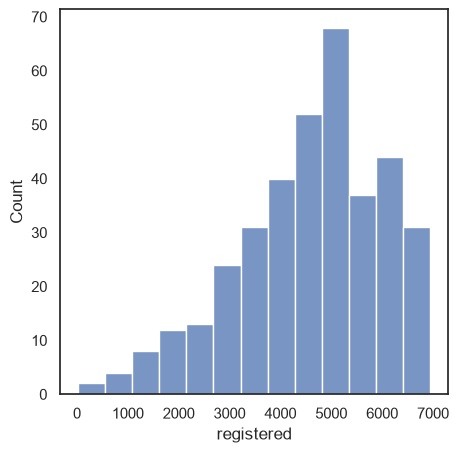

In [17]:
# [histplot : 히스토그램. 값의 범위를 여러 구간으로 나누고, 구간마다 몇 개가 들어가는지 막대로 그림]
# x='registered' : 회원 대여 건수를 x축 구간으로 나눔 → 막대 높이(Count) = 그 구간에 속한 날의 수
#   예) 어떤 구간의 막대 높이가 70 이면 → 회원 대여 건수가 그 범위였던 날이 70일
# barplot 과의 차이 : barplot 은 그룹별 '평균', histplot 은 구간별 '개수'
#
# 언제 쓰면 효과적인가?
#   - 열 하나의 값들이 어떻게 분포하는지(어디에 몰려 있는지, 한쪽으로 치우쳤는지) 볼 때
#   - 데이터가 아무리 많아도 막대 몇 개로 요약되므로 큰 데이터에도 좋음
#
# 이 그래프의 내용
#   - 4,000~6,000건 사이 막대가 가장 높음 → 대부분의 날은 회원이 이 정도 빌림
#   - 왼쪽(적은 쪽)으로 꼬리가 길게 늘어져 있음 → 가끔 아주 적게 빌린 날이 있음 (날씨가 나쁜 날 등)
#   - 오른쪽은 7,000 근처에서 뚝 끊김 → 아주 많이 빌린 날은 드묾
plt.figure(figsize=(5,5))   # 이 그래프 하나만 가로 5, 세로 5 인치
sns.histplot(data=df, x='registered')


<Axes: xlabel='Count', ylabel='registered'>

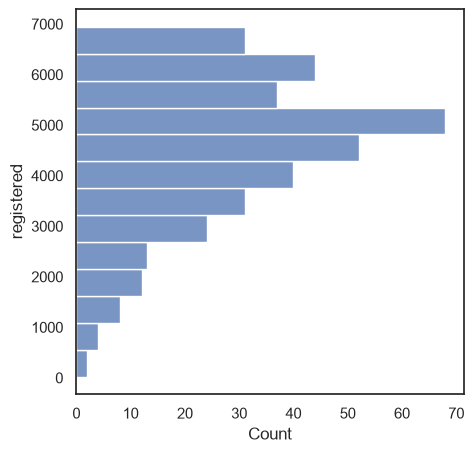

In [18]:
# x 대신 y 에 열을 넣으면 히스토그램이 옆으로 누움 (막대가 가로 방향)
# 내용은 위 그래프와 똑같고 방향만 다름. y축에 값이 있는 다른 그래프 옆에 붙여 볼 때 편함
plt.figure(figsize=(5,5))
sns.histplot(data=df, y='registered')

<Axes: xlabel='registered', ylabel='Count'>

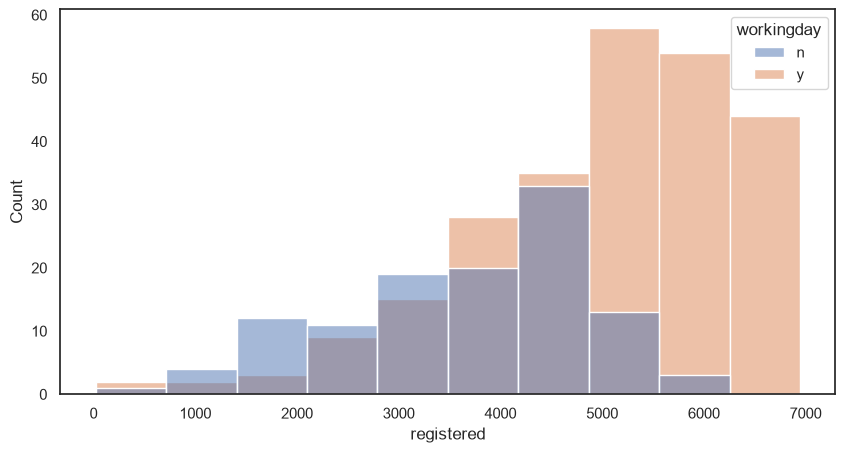

In [19]:
# bins=10 : 전체 범위(20~6,946건)를 구간 10개로 나눔. 숫자가 클수록 막대가 가늘고 많아짐
#   bins 가 너무 적으면 모양이 뭉개지고, 너무 많으면 들쭉날쭉해서 오히려 읽기 어려움
# hue='workingday' : 근무일(y) / 쉬는 날(n) 히스토그램을 색을 달리해서 겹쳐 그림
#   겹친 부분은 두 색이 섞여 보임
#
# 이 그래프의 내용
#   - 근무일(y)은 오른쪽(약 4,900~6,900건)에 몰려 있음 → 근무일엔 회원이 많이 빌림
#   - 쉬는 날(n)은 가운데(약 2,000~4,900건)에 넓게 퍼져 있고, 6,250건 넘는 날은 하루도 없음
#   - y 막대가 전체적으로 더 높은 건 근무일 수(250일)가 쉬는 날(116일)보다 많기 때문
#     → 높이보다 '어디에 몰려 있는지'를 비교해야 함
sns.histplot(data=df, x='registered',bins=10, hue='workingday')

<Axes: xlabel='registered', ylabel='Count'>

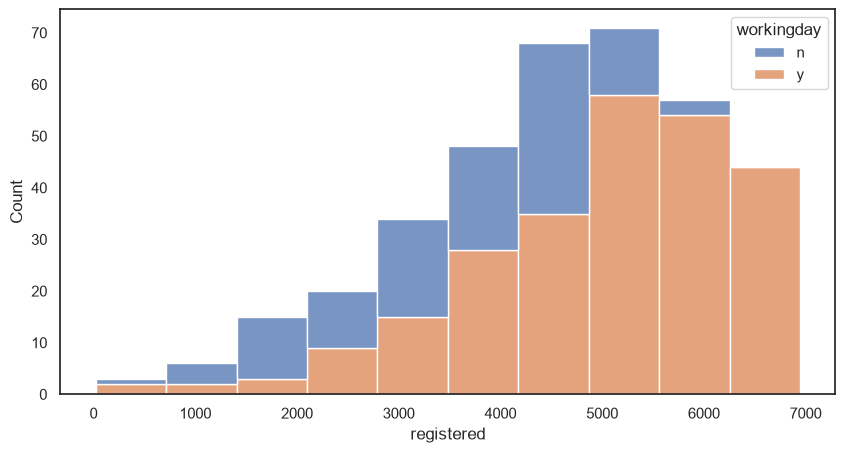

In [20]:
sns.histplot(data=df, x='registered',bins=10, hue='workingday', multiple='stack')
# multiple = 'stack' -> 겹치는 부분 없이 또 다른 막대를 그대로 쌓아서 보여줌
# 쌓은 막대의 전체 높이 = 그 구간의 전체 날 수 (y + n)
# 막대 안에서 색이 차지하는 비율 = 그 구간에서 근무일 / 쉬는 날의 비율
#   예) 오른쪽 구간은 거의 다 y 색 → 많이 빌린 날은 대부분 근무일
# 언제 쓰나 : 전체 분포와 그 안의 그룹 구성을 한 번에 보고 싶을 때
#             (겹쳐 그리면 색이 섞여 헷갈릴 때도 stack 이 더 깔끔함)

#### KDE Plot

<Axes: xlabel='registered', ylabel='Density'>

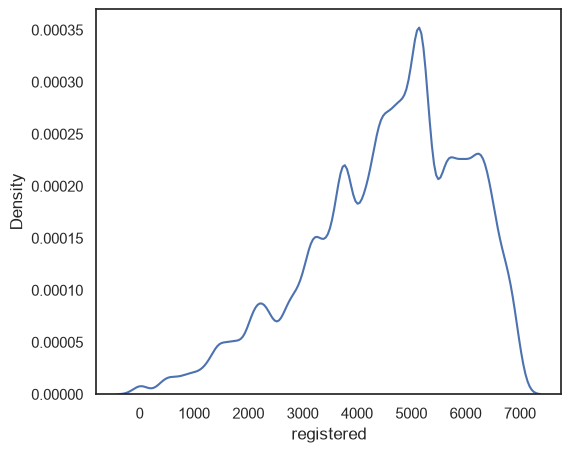

In [23]:
# [kdeplot : 히스토그램을 부드러운 곡선으로 그린 그래프 (KDE = 커널 밀도 추정)]
# 막대 대신 곡선으로 분포 모양을 보여 줌. 곡선이 높은 곳 = 그 값 근처에 데이터가 많이 몰려 있음
# y축(Density)은 개수가 아니라 비율. 곡선 아래 전체 넓이가 1 이 되도록 맞춘 값이라 숫자 자체보다 모양을 봄
# bw_method : 곡선을 얼마나 부드럽게 할지 (히스토그램의 bins 와 비슷한 역할)
#   - 작을수록(0.1) 데이터에 딱 붙어서 울퉁불퉁 → 세세한 모양까지 보임
#   - 클수록(1 등) 매끈해짐 → 큰 흐름만 보임
#
# 언제 쓰면 효과적인가?
#   - 분포 모양을 깔끔하게 보고 싶을 때 (bins 를 몇 개로 할지 고민할 필요가 적음)
#   - hue 로 여러 그룹의 분포를 겹쳐서 비교할 때 (막대보다 선이 덜 겹쳐 보여서 비교가 쉬움)
#
# 이 그래프의 내용 : 위 히스토그램과 같은 데이터
#   - 5,000건 근처가 가장 높이 솟음 → 가장 흔한 회원 대여 건수
#   - 왼쪽으로 낮고 길게 이어지는 꼬리 → 가끔 있는 적게 빌린 날
sns.set_theme(rc={'figure.figsize': (6, 5)}, style='white')
sns.kdeplot(data=df, x='registered',bw_method=0.1)

## 상관관계 시각화





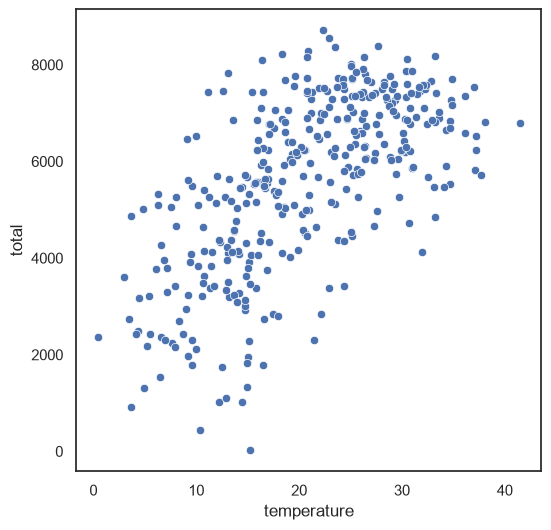

In [25]:
# [scatterplot : 산점도. 두 숫자 변수의 관계를 점으로 찍어 보는 그래프]
# 하루 = 점 1개. x = 그날 기온(temperature), y = 그날 전체 대여 건수(total)
# 점들이 오른쪽 위로 올라가면 양의 상관관계, 오른쪽 아래로 내려가면 음의 상관관계
#
# 언제 쓰면 효과적인가?
#   - 두 숫자 변수가 '같이 움직이는지' 처음 확인할 때 (상관관계 분석의 첫 단계)
#   - 직선 관계인지, 곡선 관계인지, 동떨어진 점(이상치)이 있는지 눈으로 볼 때
#
# 이 그래프에서 보면
#   - 기온이 오를수록 점들이 위로 올라감 → 따뜻할수록 자전거를 많이 탐 (양의 상관관계)
#     (기온 10도 이하 평균 약 3,400건 → 25~30도 평균 약 6,800건)
#   - 단, 30도를 넘어가면 더 이상 늘지 않고 살짝 줄어드는 모습 → 너무 더우면 덜 탐
sns.set_theme(rc={'figure.figsize': (6, 6)}, style='white')
sns.scatterplot(data=df, x='temperature', y='total')
plt.show()

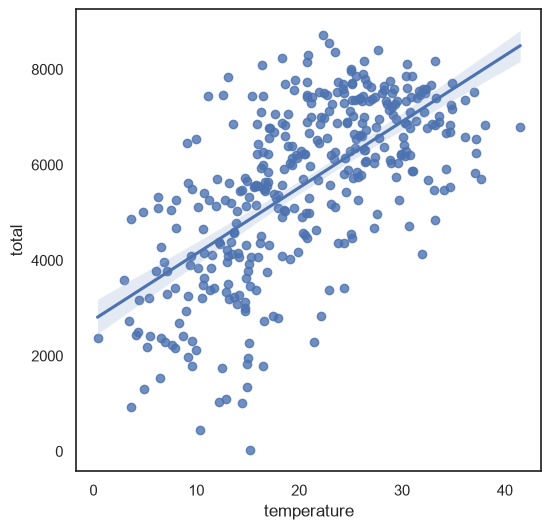

In [26]:
# [regplot : 산점도 + 회귀선(추세를 나타내는 직선)을 함께 그리는 그래프]
# 직선 = 점들의 흐름을 가장 잘 나타내는 선. 기울기가 + 면 양의 관계, - 면 음의 관계
# 선 주변 연한 띠 = 신뢰구간 (추세선이 이 범위 안에 있을 가능성이 높다는 뜻). 띠가 좁을수록 추세가 확실
#
# scatterplot 과의 차이 : 점만 찍으면 '대충 올라가네' 정도지만, 선이 있으면 방향과 기울기가 한눈에 보임
#
# 이 그래프에서 보면
#   - 선이 오른쪽 위로 뚜렷하게 올라감 → 기온과 대여 건수는 양의 상관관계 (상관계수 0.64)
#   - 점들이 선 주변에 비교적 모여 있음 → 꽤 강한 관계
sns.regplot(data=df, x='temperature', y='total')
plt.show()

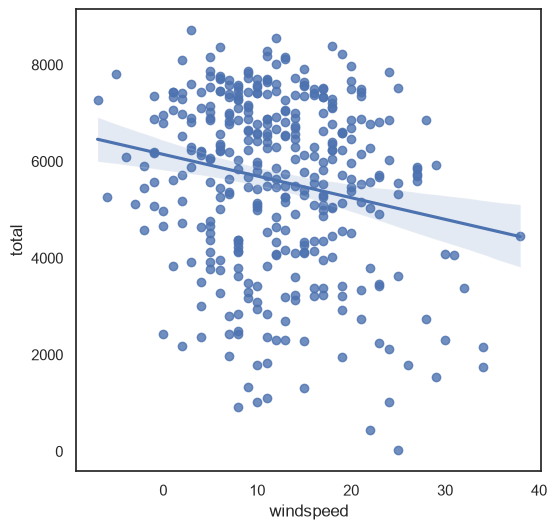

In [29]:
# [풍속(windspeed) vs 대여 건수]
# 이 그래프에서 보면
#   - 선이 오른쪽 아래로 살짝 내려감 → 바람이 셀수록 대여가 조금 줄어듦 (상관계수 -0.19, 약한 음의 상관관계)
#   - 점들이 선에서 위아래로 넓게 퍼져 있음 → 풍속만으로 대여 건수를 예측하기는 어려움
#   - 풍속 20 이하에서는 평균 약 5,700~5,900건으로 비슷하다가, 20을 넘으면 약 4,700건으로 떨어짐
#     → 바람이 '아주 셀 때'만 영향이 큼
sns.regplot(data=df, x='windspeed', y='total')
plt.show()

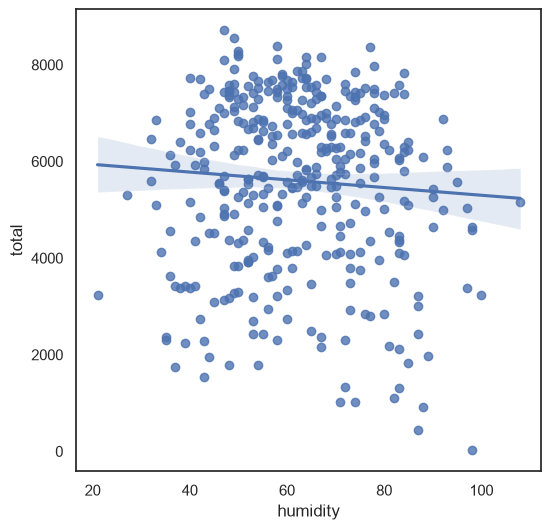

In [30]:
# [습도(humidity) vs 대여 건수]
# 이 그래프에서 보면
#   - 선이 거의 평평함 → 습도와 대여 건수는 직선 관계가 거의 없음 (상관계수 -0.07)
#   - 하지만 '아무 관계도 없다'는 뜻은 아님! 습도 40~80 에서는 평균 약 5,800~5,900건으로 많고,
#     너무 건조하거나(40 이하, 약 4,700건) 너무 습하면(80 초과, 약 4,500건) 줄어듦 → 가운데가 볼록한 곡선 관계
#   - 피어슨 상관계수는 '직선' 관계만 잡아내기 때문에 이런 곡선 관계는 0 에 가깝게 나옴
#     → 상관계수만 믿지 말고 꼭 그래프로 같이 확인해야 하는 이유
sns.regplot(data=df, x='humidity', y='total')
plt.show()

In [32]:
# [corr : 모든 숫자 열끼리의 피어슨 상관계수를 표로 계산]
# numeric_only=True : 숫자 열만 계산 (quarter, day_of_week 같은 문자 열은 계산할 수 없어서 제외)
# 표 읽는 법 : 행과 열이 만나는 칸 = 두 변수의 상관계수 (-1 ~ 1)
#   - 대각선은 자기 자신과의 상관계수라 항상 1
#   - 표는 대각선을 기준으로 대칭 (A-B 와 B-A 는 같은 값)
#
# 이 표에서 보면 (total 기준)
#   - temperature 0.64 : 날씨 변수 중 대여 건수와 가장 관계가 큼
#   - windspeed -0.19 : 약한 음의 관계 / humidity -0.07, day -0.05 : 거의 관계 없음
#   - registered 0.91, casual 0.64 : total = registered + casual 이라 높은 게 당연 (분석 의미는 적음)
df.corr(numeric_only=True)   # 상관계수 알기

,month,day,temperature,humidity,windspeed,registered,casual,total
month,1.000000,0.006443,0.128435,0.191763,-0.043407,0.281855,0.099117,0.266502
day,0.006443,1.000000,0.006938,0.092935,0.024777,-0.055827,-0.019697,-0.052814
temperature,0.128435,0.006938,1.000000,0.087400,-0.114972,0.554088,0.477538,0.643860
humidity,0.191763,0.092935,0.087400,1.000000,-0.221569,-0.049545,-0.066836,-0.067814
windspeed,-0.043407,0.024777,-0.114972,-0.221569,1.000000,-0.182959,-0.104406,-0.189995
registered,0.281855,-0.055827,0.554088,-0.049545,-0.182959,1.000000,0.274984,0.912994
casual,0.099117,-0.019697,0.477538,-0.066836,-0.104406,0.274984,1.000000,0.643305
total,0.266502,-0.052814,0.643860,-0.067814,-0.189995,0.912994,0.643305,1.000000


<Axes: >

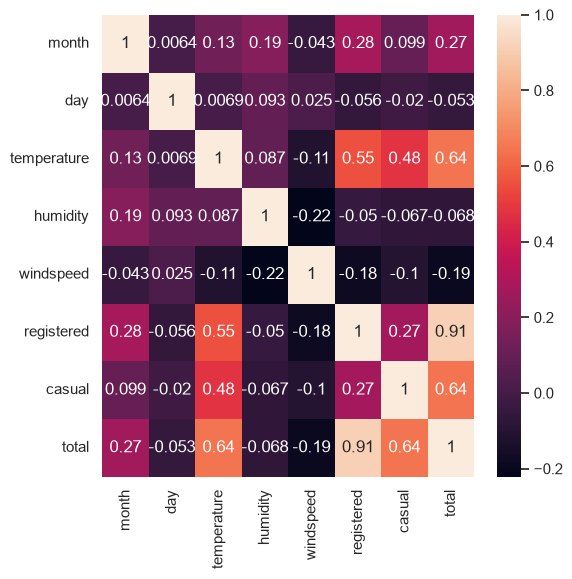

In [33]:
# [heatmap : 상관계수 표를 색으로 칠해서 보여 주는 그래프]
# annot=True : 각 칸에 숫자(상관계수 값)도 같이 표시
# 색이 밝을수록 양의 상관관계가 강하고, 어두울수록 음의 상관관계 쪽 (오른쪽 색 막대 참고)
#
# 언제 쓰면 효과적인가?
#   - 변수가 많아서 숫자 표만으로는 한눈에 안 들어올 때 → 색으로 강한 관계를 바로 찾을 수 있음
#
# 이 그래프에서 보면
#   - temperature 와 total / registered / casual 칸이 밝음 → 기온이 대여에 가장 큰 영향
#   - humidity, windspeed 줄은 대부분 어두운 쪽 → 대여와의 관계가 약함
# 참고 : 여기서는 bike_df 를 썼는데, 위의 df 와 같은 data/bike.csv 라서 결과는 같음
sns.heatmap(bike_df.corr(numeric_only=True), annot=True) # 상관계수 값 표시